Rozkład Poissona
Lambda: 4.0
Liczba wartości: 1000
Średnia z próby: 4.1110
Średnia teoretyczna: 4.0

Rozkład normalny
Mu: 0.0
Sigma: 1.0
Liczba wartości: 1000
Średnia z próby: -0.0318
Odchylenie standardowe: 0.9885


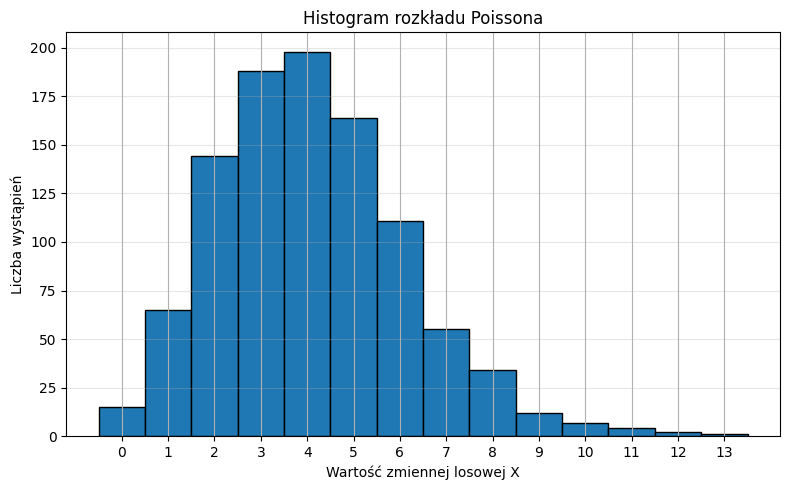

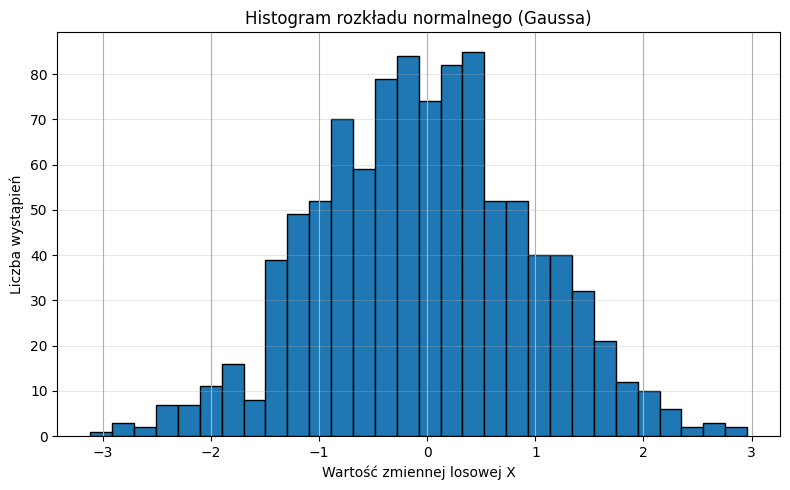

In [12]:
import math
import random
import matplotlib.pyplot as plt

N = 1000
LAMBDA = 4.0
MU = 0.0
SIGMA = 1.0
SEED = 42

rng = random.Random(SEED)


def generate_poisson(lam, n, rng):
    if lam <= 0 or n <= 0:
        raise ValueError("Lambda i liczba wartości muszą być dodatnie.")

    results = []
    q = math.exp(-lam)

    for _ in range(n):
        u = rng.random()
        x = 0
        p = q
        s = q

        while u > s:
            x += 1
            p = p * lam / x
            s += p

        results.append(x)

    return results


def generate_normal(mu, sigma, n, rng):
    if sigma <= 0 or n <= 0:
        raise ValueError("Sigma i liczba wartości muszą być dodatnie.")

    results = []

    while len(results) < n:
        u1 = rng.random()
        u2 = rng.random()

        if u1 == 0:
            continue

        z1 = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
        z2 = math.sqrt(-2 * math.log(u1)) * math.sin(2 * math.pi * u2)

        results.append(mu + sigma * z1)

        if len(results) < n:
            results.append(mu + sigma * z2)

    return results


poisson_values = generate_poisson(LAMBDA, N, rng)
normal_values = generate_normal(MU, SIGMA, N, rng)

print("Rozkład Poissona")
print(f"Lambda: {LAMBDA}")
print(f"Liczba wartości: {N}")
print(f"Średnia z próby: {sum(poisson_values) / N:.4f}")
print(f"Średnia teoretyczna: {LAMBDA}")

normal_mean = sum(normal_values) / N
normal_std = math.sqrt(
    sum((x - normal_mean) ** 2 for x in normal_values) / (N - 1)
)

print("\nRozkład normalny")
print(f"Mu: {MU}")
print(f"Sigma: {SIGMA}")
print(f"Liczba wartości: {N}")
print(f"Średnia z próby: {normal_mean:.4f}")
print(f"Odchylenie standardowe: {normal_std:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(
    poisson_values,
    bins=[x - 0.5 for x in range(max(poisson_values) + 2)],
    edgecolor="black"
)
plt.title("Histogram rozkładu Poissona")
plt.xlabel("Wartość zmiennej losowej X")
plt.ylabel("Liczba wystąpień")
plt.xticks(range(max(poisson_values) + 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(normal_values, bins=30, edgecolor="black")
plt.title("Histogram rozkładu normalnego (Gaussa)")
plt.xlabel("Wartość zmiennej losowej X")
plt.ylabel("Liczba wystąpień")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()